# Пайплайн динамического мэтчинга бизнес-доменов между вакансией и резюме

Блокнот реализует гибридный подход из ресерча как пайплайн, который получает на вход два текста и сам строит граф доменов по мере поступления документов. Готовой таксономии в коде нет, а единственным стартовым знанием служит белый список глобальных отраслей, который в текущей системе уже существует и задается конфигом

Сначала пайплайн запускается на простом примере из условия задачи и на наборе крайних случаев. Затем он запускается на открытом датасете пар резюме и вакансий, где его качество сравнивается с двумя альтернативами, а именно с RAG поверх LLM и со связкой bi-encoder и cross-encoder

Все модели этого блокнота работают локально. Эмбеддинги дает BAAI/bge-m3, роль cross-encoder выполняет BAAI/bge-reranker-v2-m3, а LLM представлена моделью Qwen2.5-7B-Instruct в 4-битной квантизации через MLX. Более легкая Qwen3-4B на этой задаче путала порядок категорий и выдавала технологии за домены, поэтому от нее пришлось отказаться. Ответы LLM и эмбеддинги кэшируются только в оперативной памяти через LRU-кэш, поэтому повторный запрос с тем же текстом в рамках одного процесса не вызывает модель, а диск не изнашивается

Количественное сравнение с альтернативами в этой версии не завершено. После почти трех часов работы LLM на датасете ячейка с cross-encoder упала из-за нехватки памяти GPU, а на повторный прогон времени не было, поэтому код сравнения оставлен без выполнения, а выводы о самом эффективном подходе опираются на демо, на обработку датасета и на замеры стоимости

## 1. Модели, датасет и пути, которые использует блокнот

Блокнот самодостаточен, и все внешние зависимости перечислены в этой ячейке. Следующая ячейка скачивает веса трех моделей и датасет с Hugging Face, и ее достаточно выполнить один раз на новой машине. Нужны macOS на Apple Silicon для MLX и пакеты mlx-lm, sentence-transformers, huggingface_hub, cachetools, scikit-learn, networkx и pandas

In [1]:
from pathlib import Path

LLM_REPO = "mlx-community/Qwen2.5-7B-Instruct-4bit"
EMB_REPO = "BAAI/bge-m3"
RERANK_REPO = "BAAI/bge-reranker-v2-m3"
DATASET_REPO = "cnamuangtoun/resume-job-description-fit"
ROOT = Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
OUT_DIR = ROOT / "data" / "output"
print(f"LLM {LLM_REPO}\nэмбеддинги {EMB_REPO}\ncross-encoder {RERANK_REPO}\nдатасет {DATASET_REPO}")

LLM mlx-community/Qwen2.5-7B-Instruct-4bit
эмбеддинги BAAI/bge-m3
cross-encoder BAAI/bge-reranker-v2-m3
датасет cnamuangtoun/resume-job-description-fit


In [ ]:
from huggingface_hub import snapshot_download

for repo in (LLM_REPO, EMB_REPO, RERANK_REPO):
    path = snapshot_download(repo, ignore_patterns=["onnx/*", "*.onnx", "imgs/*", "*.msgpack", "*.h5"])
    print(repo, "->", path)
snapshot_download(DATASET_REPO, repo_type="dataset", local_dir=RAW_DIR, allow_patterns=["*.csv"])
print("датасет ->", RAW_DIR)

## 2. Загрузка моделей, кэш в памяти и общие утилиты пайплайна

Обертка над LLM считает вызовы и время генерации, чтобы в конце можно было сравнить подходы по числу вызовов LLM и по секундам на документ и на пару. Кэш живет в оперативной памяти в LRUCache из библиотеки cachetools, который ограничен по числу записей и вытесняет самые старые, а ключ строится из полного текста промпта, поэтому любое изменение промпта приводит к новому вызову

In [2]:
import re
import json
import time
import hashlib
import warnings
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
from sentence_transformers import SentenceTransformer, CrossEncoder
from mlx_lm import load, generate
from cachetools import LRUCache

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 220)
SEED = 42
OUT_DIR.mkdir(parents=True, exist_ok=True)


class LLM:
    def __init__(self, repo, cache_size=20_000):
        self.model, self.tok = load(repo)
        self.cache = LRUCache(maxsize=cache_size)
        self.stats = defaultdict(lambda: {"calls": 0, "hits": 0, "seconds": 0.0})

    def __call__(self, prompt, max_tokens=600, tag="other"):
        key = (prompt, max_tokens)
        st = self.stats[tag]
        st["calls"] += 1
        if key in self.cache:
            st["hits"] += 1
            return self.cache[key]
        text = self.tok.apply_chat_template([{"role": "user", "content": prompt}], add_generation_prompt=True, tokenize=False)
        t0 = time.perf_counter()
        out = generate(self.model, self.tok, prompt=text, max_tokens=max_tokens, verbose=False)
        st["seconds"] += time.perf_counter() - t0
        self.cache[key] = out
        return out

    def json(self, prompt, max_tokens=600, tag="other"):
        out = self(prompt, max_tokens, tag)
        start = min([i for i in (out.find("{"), out.find("[")) if i >= 0], default=-1)
        if start < 0:
            return None
        try:
            obj, _ = json.JSONDecoder().raw_decode(out[start:])
        except json.JSONDecodeError:
            return None
        if isinstance(obj, list):
            obj = {"domains": obj} if obj and all(isinstance(x, dict) and ("canonical" in x or "mention" in x) for x in obj) else (obj[0] if obj and isinstance(obj[0], dict) else None)
        return obj


class Encoder:
    def __init__(self, repo, cache_size=200_000):
        self.model = SentenceTransformer(repo)
        self.cache = LRUCache(maxsize=cache_size)

    def __call__(self, texts, max_len=512):
        self.model.max_seq_length = max_len
        got = {t: self.cache.get((t, max_len)) for t in dict.fromkeys(texts)}
        missing = [t for t, e in got.items() if e is None]
        if missing:
            embs = self.model.encode(missing, batch_size=8, normalize_embeddings=True, show_progress_bar=False)
            for t, e in zip(missing, embs):
                self.cache[(t, max_len)] = e
                got[t] = e
        return np.array([got[t] for t in texts])


t0 = time.perf_counter()
llm = LLM(LLM_REPO)
enc = Encoder(EMB_REPO)
print(f"Модели загружены за {time.perf_counter() - t0:.0f} с")

/Users/alexasadullin/test/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/alexasadullin/test/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Fetching 9 files: 100%|██████████| 9/9 [00:00<00:00, 2666.62it/s]

Модели загружены за 15 с


## 3. Белый список отраслей как единственная стартовая конфигурация

Граф начинается с корневых узлов отраслей, и больше в нем на старте ничего нет. Каждая отрасль получает русское и английское имя, потому что пайплайн принимает тексты на обоих языках. Отрасль ИТ-продуктов и корпоративных систем нужна для межотраслевых доменов вроде CRM, ERP или интеграционных шин, которые встречаются в любой отрасли

In [3]:
GLOBAL_DOMAINS = {
    "fintech": ("Финтех", "FinTech, banking, payments, insurance, investments"),
    "telecom": ("Телеком", "Telecom operators, communications, internet providers"),
    "retail": ("Ритейл и e-commerce", "Retail chains, e-commerce, marketplaces"),
    "manufacturing": ("Производство", "Manufacturing, industrial plants, automotive, aerospace"),
    "energy": ("Энергетика", "Energy, oil and gas, utilities, renewables"),
    "government": ("Госсектор", "Government, public services, defense"),
    "healthcare": ("Здравоохранение", "Healthcare, pharma, medical devices, biotech"),
    "logistics": ("Логистика", "Logistics, transportation, supply chain"),
    "construction": ("Строительство", "Construction, real estate, facilities"),
    "media": ("Медиа", "Media, advertising, marketing, entertainment, gaming"),
    "education": ("Образование", "Education, edtech, research"),
    "it": ("ИТ и корпоративные системы", "Software products, IT services, CRM, ERP, BI, integration, cloud"),
    "consulting": ("Консалтинг", "Consulting, professional and business services, HR, legal, accounting"),
    "other": ("Прочие отрасли", "Any other industry"),
}
INDUSTRY_LIST = "\n".join(f"- {k}: {v[0]} ({v[1]})" for k, v in GLOBAL_DOMAINS.items())
pd.DataFrame([(k, v[0], v[1]) for k, v in GLOBAL_DOMAINS.items()], columns=["id", "имя", "описание"])

,id,имя,описание
0,fintech,Финтех,"FinTech, banking, payments, insurance, investments"
1,telecom,Телеком,"Telecom operators, communications, internet providers"
2,retail,Ритейл и e-commerce,"Retail chains, e-commerce, marketplaces"
3,manufacturing,Производство,"Manufacturing, industrial plants, automotive, aerospace"
4,energy,Энергетика,"Energy, oil and gas, utilities, renewables"
5,government,Госсектор,"Government, public services, defense"
6,healthcare,Здравоохранение,"Healthcare, pharma, medical devices, biotech"
7,logistics,Логистика,"Logistics, transportation, supply chain"
8,construction,Строительство,"Construction, real estate, facilities"
9,media,Медиа,"Media, advertising, marketing, entertainment, gaming"


## 4. Извлечение доменов, навыков и роли через LLM

LLM получает текст резюме или вакансии целиком и возвращает JSON со строгой схемой. Для каждого домена в нем есть упоминание на языке текста, каноническое английское имя без слов о виде работы, определение в одно предложение, дословная цитата и стаж, а для вакансии еще и приоритет требования

Каноническое имя на одном языке снимает дубли вроде банкинга и banking, а определение работает как HyDE, потому что эмбеддинг строится по развернутому описанию, а не по двум словам. Программа сверяет каждую цитату с исходным текстом и выбрасывает домен без подтверждения, что защищает граф от галлюцинаций

Промпт извлечения намеренно не просит отрасль и место в иерархии. Опыт показал, что модель на 7 млрд параметров путает порядок категорий, если решать все задачи в одном большом ответе, поэтому размещение домена в графе вынесено в отдельный короткий шаг

In [4]:
DOMAIN_RULES = """A business domain is the business area, business process or class of business system the work was about,
for example "core banking integration", "credit scoring", "telecom billing", "subscription billing",
"MES systems", "loyalty programs", "warehouse management", "insurance claims", "electronic document management".
A domain is NOT a technology or tool (Python, Kafka, React), NOT a job activity (testing, development, analytics, management),
NOT a company name or company type. The canonical name must be a faithful English normalization of the mention:
translate and shorten it, keep its meaning, never replace it with a different, broader or more popular domain,
and drop words like "testing", "development" or "automation of testing". If a phrase only names a technology,
do not output it as a domain. If the text only names a broad industry (for example "fintech"),
output that industry as a domain."""

EXTRACT_PROMPT = """You extract structured data from a {kind} for a recruiting system.
{rules}
Return JSON only, no comments:
{{"role": "standardized English job title without seniority, e.g. QA automation engineer, backend developer, electrician",
"seniority": "junior|middle|senior|lead|null",
"skills": ["up to 10 hard skills and tools, no business domains"],
"domains": [{{"mention": "domain phrase as written in the text",
"canonical": "short canonical English name of the business domain in lowercase, 2-5 words",
"description": "one English sentence that defines this domain in general terms",
"evidence": "exact short quote from the text", "years": number or null{extra}}}]}}
List at most 6 domains, most important first. If there are no business domains, return an empty list.
{kind_cap}:
{text}"""


def norm(s):
    return re.sub(r"[\s_]+", " ", str(s).lower()).strip(" .")


def akey(s):
    return " ".join(sorted(set(re.findall(r"\w+", norm(s)))))


def clean_role(s):
    return re.sub(r"\b(senior|junior|middle|lead|principal|sr|jr|head)\b\.?", " ", norm(s)).strip()


def verify_evidence(evidence, text):
    ev, tx = norm(evidence), norm(text)
    if not ev:
        return False
    if ev in tx:
        return True
    tokens = re.findall(r"\w+", ev)
    return len(tokens) >= 3 and np.mean([t in tx for t in tokens]) >= 0.85


def extract(text, kind):
    extra = ', "priority": "must|nice"' if kind == "vacancy" else ""
    prompt = EXTRACT_PROMPT.format(kind=kind, rules=DOMAIN_RULES, extra=extra, kind_cap=kind.capitalize(), text=text[:6000])
    data = llm.json(prompt, max_tokens=700, tag=f"extract_{kind}") or {}
    domains, rejected = [], []
    for d in data.get("domains") or []:
        if not isinstance(d, dict) or not (d.get("canonical") or d.get("mention")):
            continue
        d["mention"] = str(d.get("mention") or d.get("canonical"))
        d["canonical"] = norm(d.get("canonical") or d["mention"])
        d["description"] = str(d.get("description") or "")
        d["priority"] = d.get("priority") if d.get("priority") in ("must", "nice") else ("nice" if kind == "vacancy" else None)
        if verify_evidence(d.get("evidence", ""), text):
            domains.append(d)
        else:
            rejected.append(dict(d, reason="цитата не найдена в тексте"))
    sen = data.get("seniority")
    return {"role": str(data.get("role") or ""), "seniority": sen if sen in ("junior", "middle", "senior", "lead") else None,
            "skills": [s for s in data.get("skills") or [] if isinstance(s, str)], "domains": domains, "rejected": rejected}

## 5. Граф доменов, который растет вместе с потоком документов

Узел графа хранит каноническое имя, определение, синонимы из реальных упоминаний, родителей и счетчик упоминаний. Корнями служат отрасли из белого списка, а уровень узла равен длине самого длинного пути до корня, поэтому глубина появляется сама по мере роста графа

Граф допускает у одного узла несколько родителей. Когда домен одинаково относится к двум отраслям, например интеграция банковского ядра принадлежит и финтеху, и ИТ-системам, узел получает второго родителя в виде корня другой отрасли, и требование любой из этих отраслей им закрывается

In [5]:
class DomainGraph:
    def __init__(self, roots):
        self.nodes = {}
        for k, (name, desc) in roots.items():
            self.nodes[k] = {"id": k, "name": name, "description": desc, "parents": [], "aliases": [norm(name), k],
                             "count": 0, "root": True}
        self._next = 0

    def add(self, name, description, parent):
        self._next += 1
        nid = f"d{self._next:04d}"
        self.nodes[nid] = {"id": nid, "name": name, "description": description, "parents": [parent],
                           "aliases": [name], "count": 0, "root": False}
        return nid

    def ancestors(self, k):
        seen, stack = {k}, [k]
        while stack:
            for p in self.nodes[stack.pop()]["parents"]:
                if p not in seen:
                    seen.add(p)
                    stack.append(p)
        return seen

    def descendants(self, k):
        return {n for n in self.nodes if k in self.ancestors(n)}

    def roots_of(self, k):
        return {x for x in self.ancestors(k) if self.nodes[x]["root"]}

    def level(self, k):
        ps = self.nodes[k]["parents"]
        return 1 if not ps else 1 + max(self.level(p) for p in ps)

    def path(self, k):
        chain = [k]
        while self.nodes[chain[-1]]["parents"]:
            chain.append(self.nodes[chain[-1]]["parents"][0])
        return " > ".join(self.nodes[x]["name"] for x in reversed(chain))

    def card(self, k):
        n = self.nodes[k]
        return f"{n['name']}: {n['description']}"

    def to_json(self, path, links=None):
        data = {"nodes": [dict(n, level=self.level(k), path=self.path(k)) for k, n in self.nodes.items()],
                "edges": [{"child": k, "parent": p} for k, n in self.nodes.items() for p in n["parents"]],
                "links": links or []}
        Path(path).write_text(json.dumps(data, ensure_ascii=False, indent=1))

    def tree(self, min_count=0):
        lines = []
        children = defaultdict(list)
        for k, v in self.nodes.items():
            for p in v["parents"]:
                children[p].append(k)

        def weight(k):
            return sum(self.nodes[x]["count"] for x in self.descendants(k))

        def walk(k, depth):
            lines.append("    " * depth + f"{self.nodes[k]['name']} [{self.nodes[k]['count']}]")
            for c in sorted(children[k], key=lambda x: -weight(x)):
                if weight(c) >= max(min_count, 1):
                    walk(c, depth + 1)

        for r in sorted([k for k, v in self.nodes.items() if v["root"]], key=lambda x: -weight(x)):
            if weight(r) >= max(min_count, 1):
                walk(r, 0)
        return "\n".join(lines)

## 6. Линковка домена к узлу графа и размещение нового домена

Сначала домен ищется среди уже известных узлов. Точное совпадение по набору слов привязывается сразу, плотный поиск bge-m3 по карточкам и синонимам привязывает уверенные совпадения выше порога, а в серой зоне между двумя порогами LLM отвечает только на вопрос дедупликации, то есть обозначает ли новое имя тот же домен, что и один из кандидатов

Если домен новый, короткий промпт размещения решает три простые задачи. Модель проверяет, что это действительно бизнес-домен, а не технология или вид работы, выбирает одну или две отрасли из белого списка и называет одну или две более широкие категории внутри отрасли. Каждая категория проходит ту же дедупликацию, но только среди узлов своей отрасли, и новый домен встает под последней категорией цепочки

Примеры в промпте размещения взяты из областей, которых нет в демонстрационных текстах, чтобы модель не получала готовых ответов

In [6]:
SAME_PROMPT = """Deduplication of a business domain taxonomy.
New domain: "{label}" ({description}).
Candidates:
{candidates}
Is the new domain exactly the same business domain as one of the candidates (synonym, translation, abbreviation or paraphrase)?
A broader, narrower or merely related domain is NOT the same.
Return JSON only: {{"same": "<id>"}} or {{"same": null}}."""

PLACE_PROMPT = """You place a new business domain into a taxonomy for a recruiting system.
Domain: "{label}" ({description}). Phrase from the document: "{mention}".
Industries:
{industries}
Answer three questions:
1) is_domain: is it a business domain (business area, business process or class of business system)?
Technologies, tools, programming, testing and other job activities are NOT business domains.
2) industries: the industry key the domain belongs to, plus a second key only if the domain equally belongs to another industry.
3) path: 1-2 broader categories inside that industry, from the most general to the most specific, that contain the domain.
Do not repeat the industry name or the domain itself.
Examples:
"insurance claims processing" -> {{"is_domain": true, "industries": ["fintech"], "path": ["insurance", "claims management"]}}
"warehouse receiving" -> {{"is_domain": true, "industries": ["logistics", "retail"], "path": ["warehouse operations"]}}
"production scheduling" -> {{"is_domain": true, "industries": ["manufacturing"], "path": ["production management"]}}
"unit testing" -> {{"is_domain": false, "industries": ["it"], "path": []}}
Return JSON only."""

AUTO_LINK, GRAY_LINK, TOP_K = 0.88, 0.72, 5


class Linker:
    def __init__(self, graph):
        self.g = graph
        self.alias_index = {akey(a): k for k, n in graph.nodes.items() for a in n["aliases"]}
        self.alias_text = defaultdict(list)
        self.log = []

    def match(self, label, description, industry=None):
        k = self.alias_index.get(akey(label))
        if k is not None and (industry is None or industry in self.g.roots_of(k)):
            return k, "alias", 1.0
        ids = [x for x, n in self.g.nodes.items() if not n["root"] and (industry is None or industry in self.g.roots_of(x))]
        if not ids:
            return None, "new", 0.0
        q = enc([f"{label}: {description}" if description else label])[0]
        s = enc([self.g.card(x) for x in ids]) @ q
        for i, x in enumerate(ids):
            if self.alias_text[x]:
                s[i] = max(s[i], float((enc(self.alias_text[x]) @ q).max()))
        order = np.argsort(-s)[:TOP_K]
        best = float(s[order[0]])
        if best >= AUTO_LINK:
            return ids[order[0]], "auto", best
        if best >= GRAY_LINK:
            cand = [ids[i] for i in order if s[i] >= GRAY_LINK]
            lines = "\n".join(f"- id={c}: {self.g.path(c)}. {self.g.nodes[c]['description']}" for c in cand)
            ans = llm.json(SAME_PROMPT.format(label=label, description=description, candidates=lines), max_tokens=30, tag="link") or {}
            if ans.get("same") in cand:
                return ans["same"], "llm_same", best
        return None, "new", best

    def remember(self, k, label, text):
        if akey(label) not in self.alias_index:
            self.alias_index[akey(label)] = k
            self.g.nodes[k]["aliases"].append(norm(label))
        if text and text not in self.alias_text[k] and not self.g.nodes[k]["root"]:
            self.alias_text[k].append(text)

    def place(self, d):
        ans = llm.json(PLACE_PROMPT.format(label=d["canonical"], description=d["description"], mention=d["mention"],
                                           industries=INDUSTRY_LIST), max_tokens=80, tag="place") or {}
        inds = ans.get("industries") or [ans.get("industry")]
        inds = [x for x in dict.fromkeys(inds if isinstance(inds, list) else [inds]) if x in GLOBAL_DOMAINS][:2] or ["other"]
        ind = inds[0]
        path = [norm(p) for p in ans.get("path") or [] if isinstance(p, str) and norm(p)]
        path = [p for p in path if akey(p) not in (akey(d["canonical"]), akey(ind), akey(GLOBAL_DOMAINS[ind][0]))][:2]
        return ans.get("is_domain", True) is not False, inds, path

    def link(self, d, doc_id):
        text = f"{d['canonical']}: {d['description']}"
        k, how, score = self.match(d["canonical"], d["description"])
        if k is None:
            is_domain, inds, path = self.place(d)
            ind = inds[0]
            if not is_domain:
                self.log.append({"doc": doc_id, "mention": d["mention"], "canonical": d["canonical"], "node": None,
                                 "path": "не бизнес-домен", "how": "rejected", "score": round(score, 3)})
                return None
            parent = ind
            for label in path:
                pk, _, _ = self.match(label, "", industry=ind)
                if pk is None:
                    pk = self.g.add(label, "", parent)
                self.remember(pk, label, "")
                parent = pk
            k = self.g.add(d["canonical"], d["description"], parent)
            for extra in inds[1:]:
                self.g.nodes[k]["parents"].append(extra)
        self.remember(k, d["canonical"], text)
        self.remember(k, d["mention"], "")
        self.g.nodes[k]["count"] += 1
        self.log.append({"doc": doc_id, "mention": d["mention"], "canonical": d["canonical"], "node": k,
                         "path": self.g.path(k), "how": how, "score": round(score, 3)})
        return k

## 7. Направленная близость доменов и итоговый скор пары

Близость считается от требования вакансии r к опыту кандидата c. Опыт в том же узле или в его потомке закрывает требование полностью, опыт в предке закрывает его частично, а для узлов из разных веток работает мера Wu-Palmer по самому глубокому общему предку. Узлы из разных отраслей общего предка не имеют, и графовая близость для них равна нулю

$$
\mathrm{sim}(r, c) =
\begin{cases}
1, & c \in \mathrm{desc}(r) \\
\gamma^{\,\ell(r) - \ell(c)}, & c \in \mathrm{anc}(r) \\
\lambda \cdot \dfrac{2\,\ell(\mathrm{LCA})}{\ell(r) + \ell(c)}, & \text{есть общий предок} \\
0, & \text{иначе}
\end{cases}
\qquad
\mathrm{dom}_r = \max_{c}\big[\mathrm{sim}(r, c)\cdot\mathrm{strength}_c + \beta\,\mathrm{cal}(\cos(r, c))\big]
$$

Косинус после калибровки входит с малым весом β, чтобы упорядочить кандидатов внутри одного узла. Сила опыта растет с числом лет и выходит на насыщение, а доменный скор вакансии усредняет требования с весом 2 для обязательных и 1 для желательных

Итоговый скор пары складывает четыре компоненты, куда входят домены, покрытие навыков, близость ролей и соответствие грейда. Если у вакансии нет доменных требований или грейда, вес отсутствующей компоненты перераспределяется на остальные

In [7]:
GAMMA, LAMBDA, BETA = 0.6, 0.8, 0.15
WEIGHTS = {"domain": 0.35, "skills": 0.30, "role": 0.25, "seniority": 0.10}
SEN = {"junior": 0, "middle": 1, "senior": 2, "lead": 3}


def ramp(x, lo, hi):
    return float(np.clip((x - lo) / (hi - lo), 0, 1))


class Matcher:
    def __init__(self):
        self.graph = DomainGraph(GLOBAL_DOMAINS)
        self.linker = Linker(self.graph)
        self.docs = {}
        self.cal = (0.45, 0.85)

    def process(self, doc_id, text, kind):
        ex = extract(text, kind)
        kept = []
        for d in ex["domains"]:
            d["node"] = self.linker.link(d, doc_id)
            if d["node"] is None:
                ex["rejected"].append(dict(d, reason="не бизнес-домен"))
                continue
            kept.append(d)
            d["emb"] = enc([f"{d['canonical']}: {d['description']}"])[0]
            yrs = d.get("years") if isinstance(d.get("years"), (int, float)) else 1.0
            d["strength"] = 0.6 + 0.4 * (1 - np.exp(-max(yrs, 0) / 2))
        ex["domains"] = kept
        ex.update(id=doc_id, kind=kind, text=text)
        self.docs[doc_id] = ex
        return ex

    def calibrate(self):
        embs = [d["emb"] for doc in self.docs.values() for d in doc["domains"]]
        if len(embs) > 3:
            E = np.array(embs)
            sims = (E @ E.T)[np.triu_indices(len(E), 1)]
            self.cal = tuple(np.quantile(sims, [0.5, 0.99]))

    def sim(self, r, c):
        g = self.graph
        if c in g.descendants(r):
            return 1.0, "тот же узел или потомок"
        anc_r = g.ancestors(r)
        if c in anc_r:
            return GAMMA ** (g.level(r) - g.level(c)), "предок требования"
        common = anc_r & g.ancestors(c)
        if not common:
            return 0.0, "разные отрасли"
        lca = max(common, key=g.level)
        return LAMBDA * 2 * g.level(lca) / (g.level(r) + g.level(c)), f"общий предок «{g.nodes[lca]['name']}»"

    def domain_score(self, vac, res):
        if not vac["domains"]:
            return None, []
        rows, tot, wsum = [], 0.0, 0.0
        for r in vac["domains"]:
            best = (0.0, None, "нет доменов в резюме", 0.0)
            for c in res["domains"]:
                s, rel = self.sim(r["node"], c["node"])
                cosv = float(r["emb"] @ c["emb"])
                val = min(1.0, s * c["strength"] + BETA * ramp(cosv, *self.cal))
                if val > best[0]:
                    best = (val, c, rel, s)
            w = 2.0 if r["priority"] == "must" else 1.0
            tot, wsum = tot + w * best[0], wsum + w
            c = best[1]
            rows.append({"требование": r["mention"], "приоритет": r["priority"], "узел требования": self.graph.path(r["node"]),
                         "опыт кандидата": c["mention"] if c else "-", "узел опыта": self.graph.path(c["node"]) if c else "-",
                         "отношение": best[2], "граф": round(best[3], 2), "скор": round(best[0], 2),
                         "цитата": c["evidence"] if c else "-"})
        return tot / wsum, rows

    def skills_score(self, vac, res):
        if not vac["skills"] or not res["skills"]:
            return 0.0 if vac["skills"] else None
        S = enc(vac["skills"]) @ enc(res["skills"]).T
        return float(np.mean([ramp(x, 0.6, 0.85) for x in S.max(1)]))

    def role_score(self, vac, res):
        if not vac["role"] or not res["role"]:
            return None
        return ramp(float(enc([clean_role(vac["role"])])[0] @ enc([clean_role(res["role"])])[0]), 0.4, 0.8)

    def seniority_score(self, vac, res):
        if vac["seniority"] is None or res["seniority"] is None:
            return None
        return 1 - abs(SEN[vac["seniority"]] - SEN[res["seniority"]]) / 3

    def score(self, vac_id, res_id, weights=WEIGHTS):
        vac, res = self.docs[vac_id], self.docs[res_id]
        dom, rows = self.domain_score(vac, res)
        parts = {"domain": dom, "skills": self.skills_score(vac, res), "role": self.role_score(vac, res),
                 "seniority": self.seniority_score(vac, res)}
        avail = {k: v for k, v in parts.items() if v is not None and weights.get(k, 0) > 0}
        wsum = sum(weights[k] for k in avail)
        total = sum(weights[k] * v for k, v in avail.items()) / wsum if wsum else 0.0
        return {"total": total, **parts, "explain": rows}

## 8. Простой пример из условия задачи

Вакансия совпадает с примером из условия, где нужен senior-автотестировщик с Kafka, обязательным финтехом и желательным опытом интеграции банковского ядра. Семь резюме покрывают всю шкалу близости от точного совпадения до соседней отрасли, а одно из них написано по-английски

In [8]:
VACANCY = ("Нужен автотестировщик senior-уровня с обязательным отличным знанием Kafka и обязательным опытом работы в финтехе. "
           "У кандидата желателен опыт с интеграцией банковского ядра.")
RESUMES = {
    "r1_abs_integration": "Senior QA, 5 лет. Цифровой банк: автотесты на Python и pytest для адаптеров между мобильным банком и АБС ЦФТ, проверка онлайн-проводок через Kafka.",
    "r2_abs_migration": "Senior QA, 6 лет. Региональный банк: тестирование миграции счетов и остатков на новую АБС Diasoft, сверка данных после перехода. Java, Kafka, Selenium.",
    "r3_credit": "Senior тестировщик, 4 года. Розничный банк: автотесты кредитного конвейера для потребительских кредитов, интеграционные тесты через Kafka, Python.",
    "r4_acquiring": "QA lead, 7 лет. Финтех-стартап: тестирование платежного шлюза интернет-эквайринга, рекуррентные платежи и возвраты. Kafka, Python.",
    "r5_crm_retail": "Senior QA, 5 лет. Сеть магазинов одежды: тестирование интеграции CRM Bitrix24 с ERP и сайтом через Kafka, программа лояльности.",
    "r6_telecom": "Senior QA, 6 лет. Федеральный оператор связи: автотесты биллинга и тарификации звонков по CDR, Kafka, Python.",
    "r7_english": "Senior QA engineer, 6 years. Tier-1 bank: test automation for the core banking integration layer built around Temenos T24, Kafka event streaming, Python.",
}
demo = Matcher()
t0 = time.perf_counter()
demo.process("vacancy", VACANCY, "vacancy")
for rid, text in RESUMES.items():
    demo.process(rid, text, "resume")
demo.calibrate()
print(f"Обработано {len(demo.docs)} документов за {time.perf_counter() - t0:.0f} с")
v = demo.docs["vacancy"]
print(f"Вакансия: роль «{v['role']}», грейд {v['seniority']}, навыки {v['skills']}")
pd.DataFrame([{k: d.get(k) for k in ["mention", "canonical", "priority", "evidence"]} | {"узел": demo.graph.path(d["node"])} for d in v["domains"]])

Обработано 8 документов за 281 с
Вакансия: роль «QA Automation Engineer», грейд senior, навыки ['Kafka', 'automation testing', 'testing', 'Java', 'Python', 'API testing', 'Selenium', 'Jira', 'Git', 'CI/CD']


,mention,canonical,priority,evidence,узел
0,финтех,fintech,must,обязательным опытом работы в финтехе,Финтех
1,интеграция банковского ядра,core banking integration,nice,опыт с интеграцией банковского ядра,Финтех > banking > core banking integration


In [9]:
pd.DataFrame([{"резюме": rid, "роль": demo.docs[rid]["role"], "упоминание": d["mention"], "канон": d["canonical"],
               "узел": demo.graph.path(d["node"]), "лет": d.get("years")} for rid in RESUMES for d in demo.docs[rid]["domains"]])

,резюме,роль,упоминание,канон,узел,лет
0,r1_abs_integration,QA Engineer,автотесты на Python и pytest для адаптеров между мобильным банком и АБС ЦФТ,core banking integration,Финтех > banking > core banking integration,5
1,r1_abs_integration,QA Engineer,проверка онлайн-проводок через Kafka,electronic document management,Финтех > banking > electronic document management,5
2,r2_abs_migration,QA Engineer,тестирование миграции счетов и остатков на новую АБС Diasoft,core banking integration,Финтех > banking > core banking integration,6
3,r2_abs_migration,QA Engineer,сверка данных после перехода,data reconciliation,Финтех > data management > data reconciliation,6
4,r3_credit,QA Automation Engineer,автотесты кредитного конвейера для потребительских кредитов,credit scoring,Финтех > data management > credit scoring,4
5,r3_credit,QA Automation Engineer,интеграционные тесты через Kafka,core banking integration,Финтех > banking > core banking integration,4
6,r4_acquiring,QA Lead,Финтех-стартап,fintech,Финтех,7
7,r4_acquiring,QA Lead,"тестирование платежного шлюза интернет-эквайринга, рекуррентные платежи и во...",payment processing,Финтех > banking > processing > payment processing,7
8,r5_crm_retail,QA Engineer,CRM Bitrix24,crm systems,ИТ и корпоративные системы > customer relationship management > crm systems,5
9,r5_crm_retail,QA Engineer,ERP,erp systems,ИТ и корпоративные системы > enterprise systems > business process managemen...,5


Журнал линковки показывает, какие решения приняты по синониму или порогу без LLM, а какие потребовали вызова модели. По нему же видно, в каком порядке появлялись узлы, а дерево ниже показывает граф после семи резюме и одной вакансии

In [10]:
pd.DataFrame(demo.linker.log)

,doc,mention,canonical,node,path,how,score
0,vacancy,финтех,fintech,fintech,Финтех,alias,1.000
1,vacancy,интеграция банковского ядра,core banking integration,d0002,Финтех > banking > core banking integration,new,0.000
2,r1_abs_integration,автотесты на Python и pytest для адаптеров между мобильным банком и АБС ЦФТ,core banking integration,d0002,Финтех > banking > core banking integration,alias,1.000
3,r1_abs_integration,проверка онлайн-проводок через Kafka,electronic document management,d0003,Финтех > banking > electronic document management,new,0.628
4,r2_abs_migration,тестирование миграции счетов и остатков на новую АБС Diasoft,core banking integration,d0002,Финтех > banking > core banking integration,alias,1.000
5,r2_abs_migration,сверка данных после перехода,data reconciliation,d0005,Финтех > data management > data reconciliation,new,0.682
6,r3_credit,автотесты кредитного конвейера для потребительских кредитов,credit scoring,d0006,Финтех > data management > credit scoring,new,0.698
7,r3_credit,интеграционные тесты через Kafka,core banking integration,d0002,Финтех > banking > core banking integration,alias,1.000
8,r4_acquiring,Финтех-стартап,fintech,fintech,Финтех,alias,1.000
9,r4_acquiring,"тестирование платежного шлюза интернет-эквайринга, рекуррентные платежи и во...",payment processing,d0008,Финтех > banking > processing > payment processing,new,0.728


In [11]:
print(demo.graph.tree())

Финтех [2]
    banking [0]
        core banking integration [4]
        electronic document management [1]
        processing [0]
            payment processing [1]
        core banking systems [0]
            temenos t24 [1]
    data management [0]
        data reconciliation [1]
        credit scoring [1]
        core banking [1]
ИТ и корпоративные системы [0]
    data reconciliation [1]
    customer relationship management [0]
        crm systems [1]
    enterprise systems [0]
        business process management [0]
            erp systems [1]
    software products [0]
        integration [1]
Телеком [1]
    loyalty programs [1]
    billing [0]
        telecom billing [1]
Ритейл и e-commerce [0]
    customer loyalty [0]
        rewards programs [0]
            loyalty programs [1]
Производство [0]
    erp systems [1]


In [12]:
rows = []
for rid in RESUMES:
    s = demo.score("vacancy", rid)
    top = s["explain"][-1] if s["explain"] else {}
    rows.append({"резюме": rid, "итог": round(s["total"], 3), "домены": round(s["domain"], 3), "навыки": round(s["skills"] or 0, 2),
                 "роль": round(s["role"] or 0, 2), "грейд": s["seniority"], "желательный домен": top.get("опыт кандидата"),
                 "отношение": top.get("отношение"), "граф": top.get("граф")})
demo_rank = pd.DataFrame(rows).sort_values("итог", ascending=False)
cos_whole = enc(list(RESUMES.values()), 1024) @ enc([VACANCY], 1024)[0]
demo_rank["cos целиком"] = demo_rank["резюме"].map(dict(zip(RESUMES, cos_whole.round(3))))
demo_rank

,резюме,итог,домены,навыки,роль,грейд,желательный домен,отношение,граф,cos целиком
2,r3_credit,0.816,0.969,0.42,1.00,1.0,интеграционные тесты через Kafka,тот же узел или потомок,1.00,0.727
0,r1_abs_integration,0.712,0.988,0.42,0.56,1.0,автотесты на Python и pytest для адаптеров между мобильным банком и АБС ЦФТ,тот же узел или потомок,1.00,0.677
1,r2_abs_migration,0.678,0.988,0.31,0.56,1.0,тестирование миграции счетов и остатков на новую АБС Diasoft,тот же узел или потомок,1.00,0.630
6,r7_english,0.667,0.808,0.48,0.56,1.0,Temenos T24,общий предок «banking»,0.46,0.617
3,r4_acquiring,0.577,0.828,0.21,0.50,1.0,"тестирование платежного шлюза интернет-эквайринга, рекуррентные платежи и во...",общий предок «banking»,0.46,0.602
5,r6_telecom,0.417,0.005,0.58,0.56,1.0,-,нет доменов в резюме,0.00,0.619
4,r5_crm_retail,0.346,0.027,0.32,0.56,1.0,integration,разные отрасли,0.00,0.577


In [13]:
pd.DataFrame(demo.score("vacancy", demo_rank["резюме"].iloc[0])["explain"])

,требование,приоритет,узел требования,опыт кандидата,узел опыта,отношение,граф,скор,цитата
0,финтех,must,Финтех,интеграционные тесты через Kafka,Финтех > banking > core banking integration,тот же узел или потомок,1.0,0.95,интеграционные тесты через Kafka
1,интеграция банковского ядра,nice,Финтех > banking > core banking integration,интеграционные тесты через Kafka,Финтех > banking > core banking integration,тот же узел или потомок,1.0,1.00,интеграционные тесты через Kafka


Граф для восьми документов построен без единого домена, который кто-то задал заранее, и интеграция банковского ядра из вакансии, из резюме про адаптеры к АБС и из резюме про миграцию АБС попала в один узел. Кандидат с точным опытом занимает только второе место, потому что модель назвала интеграционные тесты через Kafka в резюме про кредитный конвейер интеграцией банковского ядра, и эта ошибка извлечения дала чужому кандидату полное совпадение

Англоязычное резюме с тем же опытом гибрид ставит четвертым, так как модель выделила из него Temenos T24 отдельным доменом вместо интеграции с банковским ядром. Косинус целых текстов дает две ошибки порядка сразу, потому что ставит кредитный конвейер первым с оценкой 0.73 против 0.68, а англоязычного кандидата опускает ниже кандидата из телекома с оценкой 0.617 против 0.619

Объяснение для рекрутера показывает цитату, на которой держится каждая оценка, поэтому ошибку извлечения видно сразу и ее можно исправить правкой синонимов в графе

## 9. Крайние случаи с полисемией, асимметрией требования и новыми доменами

Каждый случай запускается тем же пайплайном на том же графе, поэтому новые документы продолжают его наращивать. Ниже собраны полисемия, асимметрия требования, новый домен, синоним через аббревиатуру, вакансия без доменных требований и защита от доменов без подтверждения в тексте

In [14]:
def run_case(title, vacancy, resumes):
    vid = f"{title}:vac"
    demo.process(vid, vacancy, "vacancy")
    for rid, text in resumes.items():
        demo.process(f"{title}:{rid}", text, "resume")
    demo.calibrate()
    rows = []
    for rid in resumes:
        s = demo.score(vid, f"{title}:{rid}")
        e = s["explain"][0] if s["explain"] else {}
        rows.append({"случай": title, "резюме": rid, "итог": round(s["total"], 3),
                     "доменов в вакансии": len(demo.docs[vid]["domains"]),
                     "отклонено": "; ".join(f"{x['mention']} ({x['reason']})" for x in demo.docs[vid]["rejected"]) or "-",
                     "домены": None if s["domain"] is None else round(s["domain"], 3),
                     "требование": e.get("требование"), "опыт": e.get("опыт кандидата"), "отношение": e.get("отношение")})
    return pd.DataFrame(rows)


cases = [
    run_case("полисемия", "Ищем системного аналитика с опытом в биллинге оператора связи, тарификация услуг.",
             {"телеком_биллинг": "Системный аналитик, 4 года. Мобильный оператор: требования к биллингу, тарификация трафика и звонков, выставление счетов абонентам.",
              "saas_биллинг": "Системный аналитик, 4 года. SaaS-компания: биллинг подписок, рекуррентные списания через Stripe, тарифные планы для клиентов."}),
    run_case("асимметрия_широкое", "Нужен Java-разработчик, обязателен опыт в финтехе.",
             {"узкий_опыт": "Java-разработчик, 5 лет. Банк: разработка кредитного конвейера для ипотеки и автокредитов.",
              "широкий_опыт": "Java-разработчик, 5 лет. Работал в финтех-компании, разработка внутренних сервисов."}),
    run_case("асимметрия_узкое", "Нужен Java-разработчик, обязателен опыт разработки кредитного конвейера.",
             {"узкий_опыт": "Java-разработчик, 5 лет. Банк: разработка кредитного конвейера для ипотеки и автокредитов.",
              "широкий_опыт": "Java-разработчик, 5 лет. Работал в финтех-компании, разработка внутренних сервисов."}),
    run_case("новый_домен", "Ищем продуктового аналитика, желателен опыт с BNPL, то есть сервисами оплаты покупок частями.",
             {"сплит": "Продуктовый аналитик, 3 года. Финтех: аналитика сервиса оплаты долями, сплит-платежи для интернет-магазинов.",
              "ипотека": "Продуктовый аналитик, 3 года. Банк: аналитика ипотечных продуктов и воронки заявок."}),
    run_case("аббревиатура", "Нужен frontend-разработчик с опытом в ДБО для юридических лиц.",
             {"интернет_банк": "Frontend-разработчик, 4 года. Банк: интернет-банк для корпоративных клиентов, платежные поручения, React.",
              "маркетплейс": "Frontend-разработчик, 4 года. Маркетплейс: кабинет продавца, каталог товаров, React."}),
    run_case("без_домена", "Нужен middle Python-разработчик, Django, PostgreSQL.",
             {"python_банк": "Middle Python-разработчик, 3 года. Банк: Django-сервисы для скоринга кредитных заявок, PostgreSQL.",
              "python_игры": "Middle Python-разработчик, 3 года. Игровая студия: Django-бэкенд для мобильной игры, PostgreSQL."}),
]
pd.concat(cases, ignore_index=True)

,случай,резюме,итог,доменов в вакансии,отклонено,домены,требование,опыт,отношение
0,полисемия,телеком_биллинг,0.756,2,-,0.756,биллинг оператора связи,тарификация трафика,тот же узел или потомок
1,полисемия,saas_биллинг,0.616,2,-,0.341,биллинг оператора связи,тарифные планы для клиентов,общий предок «Телеком»
2,асимметрия_широкое,узкий_опыт,0.821,1,-,0.967,финтех,разработка кредитного конвейера для ипотеки и автокредитов,тот же узел или потомок
3,асимметрия_широкое,широкий_опыт,1.000,1,-,1.000,финтех,финтех-компании,тот же узел или потомок
4,асимметрия_узкое,узкий_опыт,0.833,1,-,1.000,credit processing,разработка кредитного конвейера для ипотеки и автокредитов,тот же узел или потомок
5,асимметрия_узкое,широкий_опыт,0.580,1,-,0.348,credit processing,финтех-компании,предок требования
6,новый_домен,сплит,0.338,2,-,0.338,BNPL services,Финтех,предок требования
7,новый_домен,ипотека,0.264,2,-,0.264,BNPL services,аналитика ипотечных продуктов и воронки заявок,общий предок «Финтех»
8,аббревиатура,интернет_банк,0.589,1,-,0.589,ДБО для юридических лиц,интернет-банк для корпоративных клиентов,общий предок «finance»
9,аббревиатура,маркетплейс,0.000,1,-,0.000,ДБО для юридических лиц,-,нет доменов в резюме


In [15]:
fake = {"domains": [{"mention": "страховые выплаты", "evidence": "урегулирование убытков по КАСКО"},
                    {"mention": "кредитный конвейер", "evidence": "разработка кредитного конвейера"}]}
text = "Java-разработчик, 5 лет. Банк: разработка кредитного конвейера для ипотеки и автокредитов."
pd.DataFrame([{"упоминание": d["mention"], "цитата": d["evidence"], "цитата найдена в тексте": verify_evidence(d["evidence"], text)}
              for d in fake["domains"]])

,упоминание,цитата,цитата найдена в тексте
0,страховые выплаты,урегулирование убытков по КАСКО,False
1,кредитный конвейер,разработка кредитного конвейера,True


Почти все крайние случаи проходят проверку. Полисемия разводит биллинг оператора связи и биллинг подписок до 0.76 против 0.34, а направленная мера различает оба направления требования, так как опыт в кредитном конвейере закрывает требование финтеха на 0.97, а опыт работы в финтех-компании закрывает требование кредитного конвейера только на 0.35

Новый домен BNPL проходит лишь формально. Резюме про оплату долями обходит ипотеку с оценкой 0.34 против 0.26, но обе оценки держатся только на общем корне финтеха, потому что модель не связала оплату долями с BNPL

Аббревиатура ДБО связалась с интернет-банком для корпоративных клиентов через общего предка, а у маркетплейса доменный скор равен нулю. Вакансия без доменов дает обоим кандидатам одинаковый скор, и это верное поведение, так как без доменного требования скоринг опирается только на навыки, роль и грейд, а домен без цитаты в тексте отбрасывается еще на этапе извлечения

В графе остались дубли вроде программ лояльности под ритейлом и под телекомом, потому что поиск широких категорий ограничен своей отраслью. Слияние таких узлов через второго родителя стоит добавить следующим шагом

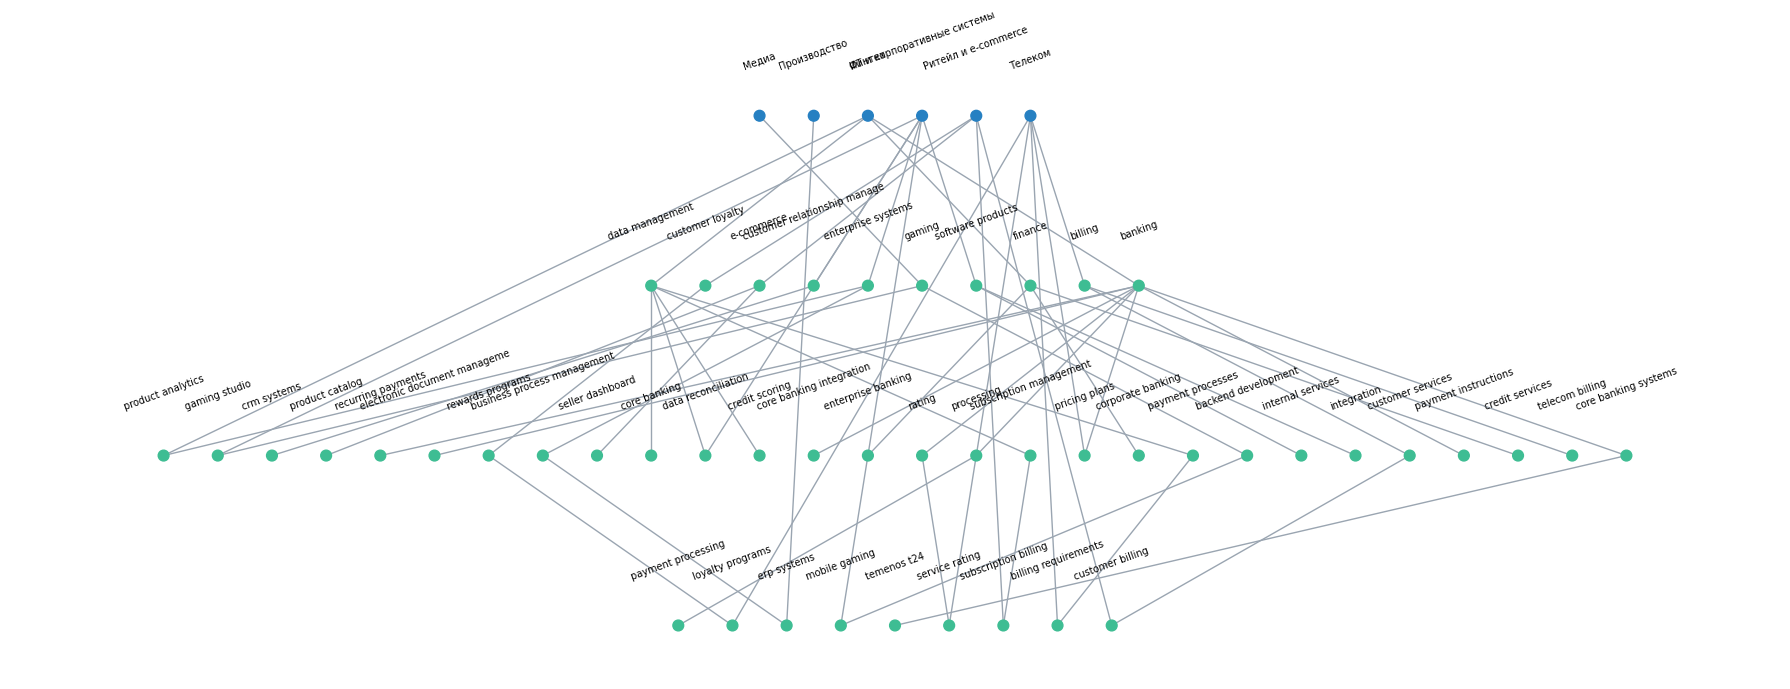

Узлов в графе 62, сохранено в /Users/alexasadullin/test/data/output/demo_graph.json


In [16]:
def draw_graph(graph, path, min_count=1):
    keep = {k for k, n in graph.nodes.items() if not n["root"] and n["count"] >= min_count}
    keep |= {a for k in keep for a in graph.ancestors(k)}
    G = nx.DiGraph()
    for k in keep:
        G.add_node(k, label=graph.nodes[k]["name"][:28])
        for p in graph.nodes[k]["parents"]:
            if p in keep:
                G.add_edge(p, k)
    depth = {k: graph.level(k) for k in G}
    for k in G:
        G.nodes[k]["layer"] = depth[k]
    pos = nx.multipartite_layout(G, subset_key="layer", align="horizontal")
    pos = {k: (x, -y) for k, (x, y) in pos.items()}
    fig, ax = plt.subplots(figsize=(18, 7))
    nx.draw_networkx_edges(G, pos, ax=ax, arrows=False, edge_color="#9aa5b1")
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=60,
                           node_color=["#2680c2" if graph.nodes[k]["root"] else "#3ebd93" for k in G])
    for k, (x, y) in pos.items():
        ax.text(x, y + 0.02, G.nodes[k]["label"], fontsize=7, ha="center", rotation=20)
    ax.axis("off")
    plt.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()


demo.graph.to_json(OUT_DIR / "demo_graph.json", demo.linker.log)
draw_graph(demo.graph, OUT_DIR / "demo_graph.png")
print(f"Узлов в графе {len(demo.graph.nodes)}, сохранено в {OUT_DIR / 'demo_graph.json'}")

## 10. Датасет пар резюме и вакансий для сравнения подходов

Открытого русскоязычного датасета с разметкой соответствия нет, поэтому для замера взят англоязычный cnamuangtoun/resume-job-description-fit с Hugging Face. Каждая пара в нем размечена как Good Fit, Potential Fit или No Fit, а вакансии повторяются, так что внутри одной вакансии кандидатов можно ранжировать

Из тестовой части выбраны вакансии, где есть и подходящие, и неподходящие кандидаты, и для каждой взято не больше 15 пар со стратификацией по метке. Такой объем рассчитан примерно на три часа работы локальной LLM, а платой за него служат широкие доверительные интервалы метрик

In [17]:
N_JD, MAX_PER_JD = 12, 15
GAIN = {"No Fit": 0, "Potential Fit": 1, "Good Fit": 2}
raw = pd.read_csv(RAW_DIR / "test.csv")
raw["gain"] = raw.label.map(GAIN)
raw["jd_id"] = raw.job_description_text.map(lambda t: "jd_" + hashlib.sha1(t.encode()).hexdigest()[:10])
raw["cv_id"] = raw.resume_text.map(lambda t: "cv_" + hashlib.sha1(t.encode()).hexdigest()[:10])
stats = raw.groupby("jd_id").gain.agg(n="size", fit=lambda s: (s > 0).sum(), nofit=lambda s: (s == 0).sum())
eligible = stats[(stats.fit > 0) & (stats.nofit > 0) & (stats.n >= 6)].index
rs = np.random.RandomState(SEED)
jds = sorted(rs.choice(eligible, size=min(N_JD, len(eligible)), replace=False))
parts = []
for jd in jds:
    d = raw[raw.jd_id == jd]
    if len(d) > MAX_PER_JD:
        frac = MAX_PER_JD / len(d)
        d = d.groupby("gain", group_keys=False).apply(lambda x: x.sample(max(1, int(round(len(x) * frac))), random_state=SEED))
    parts.append(d)
bench = pd.concat(parts, ignore_index=True)
JD_TEXT = dict(zip(bench.jd_id, bench.job_description_text))
CV_TEXT = dict(zip(bench.cv_id, bench.resume_text))
print(f"Вакансий {bench.jd_id.nunique()}, резюме {bench.cv_id.nunique()}, пар {len(bench)}")
print(bench.label.value_counts().to_dict())

Вакансий 12, резюме 124, пар 154
{'No Fit': 67, 'Good Fit': 50, 'Potential Fit': 37}


## 11. Гибридный пайплайн на датасете

Пайплайн обрабатывает каждый документ один раз, и граф растет на всем потоке вакансий и резюме, начиная с тех же корней из белого списка. Скоринг пары после этого не требует вызовов LLM и сводится к поиску по графу и паре скалярных произведений

In [18]:
hyb = Matcher()
llm.stats.clear()
t0 = time.perf_counter()
for i, (jd, text) in enumerate(JD_TEXT.items()):
    hyb.process(jd, text, "vacancy")
for i, (cv, text) in enumerate(CV_TEXT.items()):
    hyb.process(cv, text, "resume")
    if (i + 1) % 50 == 0:
        print(f"резюме {i + 1}/{len(CV_TEXT)}, узлов {len(hyb.graph.nodes)}, {time.perf_counter() - t0:.0f} с", flush=True)
hyb.calibrate()
t_offline = time.perf_counter() - t0
hyb.graph.to_json(OUT_DIR / "benchmark_graph.json", hyb.linker.log)
print(f"Офлайн-обработка {len(JD_TEXT) + len(CV_TEXT)} документов заняла {t_offline / 60:.1f} мин, узлов в графе {len(hyb.graph.nodes)}")
link_stats = pd.DataFrame(hyb.linker.log).how.value_counts()
print("Решения линковки:", link_stats.to_dict())

резюме 50/124, узлов 322, 6482 с


резюме 100/124, узлов 445, 12135 с


Офлайн-обработка 136 документов заняла 238.3 мин, узлов в графе 510
Решения линковки: {'new': 366, 'alias': 319, 'auto': 20, 'rejected': 1}


In [19]:
t0 = time.perf_counter()
scores = [hyb.score(jd, cv) for jd, cv in zip(bench.jd_id, bench.cv_id)]
t_hyb_pair = (time.perf_counter() - t0) / len(bench)
for k in ["total", "domain", "skills", "role", "seniority"]:
    bench[f"hyb_{k}"] = [s[k] for s in scores]
bench["hyb_domain_only"] = bench.hyb_domain.fillna(0)
docs_with_domains = np.mean([len(d["domains"]) > 0 for d in hyb.docs.values()])
print(f"Скоринг пары {t_hyb_pair * 1000:.1f} мс, документов хотя бы с одним доменом {docs_with_domains:.0%}")
print(hyb.graph.tree(min_count=3)[:3000])

Скоринг пары 185.5 мс, документов хотя бы с одним доменом 93%


ИТ и корпоративные системы [1]
    collaboration [31]
        cloud services [5]
            engineering [1]
                billing [2]
                    recurring services [0]
                        subscription billing [3]
                tax preparation [3]
        product development [4]
            data analytics [1]
                ai and machine learning [0]
                    machine learning [2]
        agile methodologies [0]
            agile [12]
        web development [9]
        administration [2]
        business process management [2]
        meeting management [0]
            web services [3]
        mobile app development [3]
        system analysis [2]
    data processing [2]
        data management [5]
            integration [11]
                data integration [1]
                    etl [8]
                data warehousing [8]
            testing [3]
            business analytics [0]
                data analysis [12]
            database management [8]
 

Пайплайн обработал все 136 документов, и хотя бы один домен нашелся в 93% из них. Граф вырос до 510 узлов, где 366 упоминаний создали новые узлы, 319 нашли готовый узел по синониму, а 20 привязались по близости эмбеддингов

На этом датасете в граф попали узлы, которые описывают вид работы, а не бизнес-домен. Фильтр не-доменов отсек всего одно упоминание из 706 решений, поэтому узлами стали agile, web development, customer service и другие виды работы, а часть цепочек потеряла смысл, как в ветке finance > compliance > environment > reception. Датасет содержит много резюме бухгалтеров, администраторов и электриков, где граница между доменом и обязанностью размыта, и модель на 7 млрд параметров по этой границе почти не отсекает упоминания

Обработка одного длинного документа заняла от 60 до 105 секунд, а скоринг пары занял 185 мс. Второе число объясняет реализация MVP, которая на каждый вызов заново ищет потомков узла, и после предварительного расчета транзитивного замыкания скоринг займет доли миллисекунды. Таймер в выводе выше показывает 238 минут, потому что он учитывает и паузы, когда процесс стоял замороженным

## Почему сравнение с альтернативами осталось без выполнения

Ячейки разделов 12-15 в этой версии не выполнены. Bi-encoder кодирует резюме целиком с окном 2048 токенов, и после трех часов генерации MLX удерживал почти всю общую память GPU, поэтому PyTorch не смог выделить 55 МБ и ячейка упала с ошибкой нехватки памяти MPS

Вместе с ядром пропали результаты извлечения по всем документам, а повторный прогон занял бы еще около четырех часов. Код сравнения оставлен без изменений, и его можно запустить на машине с запасом памяти или после двух правок, где кэш MLX ограничивается через mx.set_cache_limit, а результаты извлечения один раз сохраняются в data/output как выход пайплайна

## 12. Альтернатива bi-encoder и cross-encoder

Bi-encoder bge-m3 кодирует вакансию и резюме целиком и ранжирует кандидатов по косинусу. Затем cross-encoder bge-reranker-v2-m3 переоценивает топ-10 каждой вакансии, а остальные кандидаты сохраняют порядок bi-encoder, как и происходит в типичной двухстадийной схеме поиска

In [ ]:
t0 = time.perf_counter()
E_jd = dict(zip(JD_TEXT, enc(list(JD_TEXT.values()), 2048)))
E_cv = dict(zip(CV_TEXT, enc(list(CV_TEXT.values()), 2048)))
t_bi = time.perf_counter() - t0
bench["bi"] = [float(E_jd[j] @ E_cv[c]) for j, c in zip(bench.jd_id, bench.cv_id)]

reranker = CrossEncoder(RERANK_REPO, max_length=2048)
RERANK_TOP = 10
t0 = time.perf_counter()
ce = np.full(len(bench), np.nan)
for jd, d in bench.groupby("jd_id"):
    top = d.sort_values("bi", ascending=False).head(RERANK_TOP).index
    ce[top] = reranker.predict([(JD_TEXT[jd], CV_TEXT[c]) for c in bench.loc[top, "cv_id"]], batch_size=2, show_progress_bar=False)
t_ce = time.perf_counter() - t0
bench["ce_raw"] = ce
bench["bi_ce"] = np.where(np.isnan(ce), bench.bi - 10, 10 + np.nan_to_num(ce))
print(f"bi-encoder {t_bi:.0f} с на {len(JD_TEXT) + len(CV_TEXT)} документов, cross-encoder {t_ce:.0f} с на {int((~np.isnan(ce)).sum())} пар")

## 13. Альтернатива RAG поверх LLM

Для каждой пары RAG достает из резюме четыре фрагмента, которые ближе всего к тексту вакансии по bge-m3, и передает их в ту же локальную LLM вместе с вакансией. Модель возвращает оценку от 0 до 10 и короткое обоснование, поэтому стоимость здесь растет с числом пар, а не с числом документов

In [ ]:
RAG_PROMPT = """You are an experienced recruiter. Rate how well the candidate fits the job on a 0-10 scale
(0 = no fit, 10 = perfect fit). Consider role, required skills, seniority and business domain experience.
Job description:
{jd}
Most relevant resume excerpts:
{chunks}
Return JSON only: {{"score": <integer 0-10>, "reason": "<at most 20 words>"}}"""


def chunks(text, size=700):
    parts = re.split(r"(?<=[.!?])\s+", text)
    out, cur = [], ""
    for p in parts:
        if len(cur) + len(p) > size and cur:
            out.append(cur)
            cur = ""
        cur += p + " "
    return out + ([cur] if cur.strip() else [])


t0 = time.perf_counter()
rag = []
for i, (jd, cv) in enumerate(zip(bench.jd_id, bench.cv_id)):
    ch = chunks(CV_TEXT[cv])
    sims = enc(ch, 512) @ E_jd[jd]
    top = [ch[j] for j in np.argsort(-sims)[:4]]
    ans = llm.json(RAG_PROMPT.format(jd=JD_TEXT[jd][:3000], chunks="\n---\n".join(top)), max_tokens=80, tag="rag") or {}
    sc = ans.get("score")
    rag.append(float(sc) if isinstance(sc, (int, float)) else np.nan)
    if (i + 1) % 100 == 0:
        print(f"пар {i + 1}/{len(bench)}, {time.perf_counter() - t0:.0f} с", flush=True)
bench["rag"] = rag
t_rag = time.perf_counter() - t0
print(f"RAG + LLM {t_rag / 60:.1f} мин, нераспознанных ответов {np.isnan(rag).sum()}")

## 14. Сравнение методов по метрикам ранжирования

Метрики считаются внутри каждой вакансии и затем усредняются. nDCG@5 и nDCG@10 используют выигрыш 2 для Good Fit и 1 для Potential Fit, ROC-AUC отделяет любых подходящих кандидатов от неподходящих, а Spearman на всех парах показывает согласие скора с трехуровневой меткой. Доверительные интервалы получены бутстрепом по вакансиям

In [ ]:
def ndcg(scores, gains, k):
    order = np.argsort(-scores, kind="stable")[:k]
    disc = 1 / np.log2(np.arange(2, len(order) + 2))
    ideal = np.sort(gains)[::-1][:k]
    idcg = (ideal * disc[:len(ideal)]).sum()
    return (gains[order] * disc).sum() / idcg if idcg > 0 else np.nan


METHODS = {"bi-encoder bge-m3": "bi", "bi-encoder + cross-encoder": "bi_ce", "RAG + LLM": "rag",
           "гибрид, только домены": "hyb_domain_only", "гибрид, полный скор": "hyb_total"}
noise = np.random.RandomState(SEED).rand(len(bench)) * 1e-9
per_jd = []
for jd, d in bench.groupby("jd_id"):
    g = d.gain.values.astype(float)
    for name, col in METHODS.items():
        s = d[col].fillna(d[col].min()).values + noise[d.index]
        per_jd.append({"jd": jd, "метод": name, "nDCG@5": ndcg(s, g, 5), "nDCG@10": ndcg(s, g, 10),
                       "ROC-AUC": roc_auc_score(g > 0, s)})
per_jd = pd.DataFrame(per_jd)


def boot_ci(x, n=2000):
    rs = np.random.RandomState(SEED)
    m = [np.mean(rs.choice(x, len(x))) for _ in range(n)]
    return np.quantile(m, [0.025, 0.975])


summary = []
for name, col in METHODS.items():
    p = per_jd[per_jd["метод"] == name]
    lo, hi = boot_ci(p["nDCG@10"].values)
    summary.append({"метод": name, "nDCG@5": p["nDCG@5"].mean(), "nDCG@10": p["nDCG@10"].mean(), "95% ДИ nDCG@10": f"{lo:.3f}-{hi:.3f}",
                    "ROC-AUC": p["ROC-AUC"].mean(), "Spearman": spearmanr(bench[col].fillna(bench[col].min()), bench.gain).correlation})
summary = pd.DataFrame(summary).set_index("метод")
summary.round(3)

In [ ]:
st = llm.stats
n_docs, n_pairs, n_ce = len(JD_TEXT) + len(CV_TEXT), len(bench), int((~np.isnan(ce)).sum())
hyb_calls = sum(st[k]["calls"] for k in ("extract_vacancy", "extract_resume", "link"))
cost = pd.DataFrame({
    "офлайн на документ, с": [t_bi / n_docs, t_bi / n_docs, 0.0, t_offline / n_docs],
    "вызовов LLM на документ": [0, 0, 0, hyb_calls / n_docs],
    "вызовов LLM на пару": [0, 0, 1, 0],
    "онлайн на пару, мс": [0.01, t_ce / max(1, n_ce) * 1000, t_rag / n_pairs * 1000, t_hyb_pair * 1000],
}, index=["bi-encoder bge-m3", "bi-encoder + cross-encoder", "RAG + LLM", "гибрид, полный скор"])
cost.round(2)

## 15. Вклад компонент гибридного скора

Абляция показывает, сколько дает каждая компонента по отдельности и что происходит без доменной части. Датасет размечен по общему соответствию, а не по доменам, поэтому роль и навыки здесь закономерно весят больше, а доменная компонента отвечает за различение кандидатов внутри одной роли

In [ ]:
abl = {"только домены": {"domain": 1}, "только навыки": {"skills": 1}, "только роль": {"role": 1},
       "без доменов": {"skills": 0.30, "role": 0.25, "seniority": 0.10}, "полный скор": WEIGHTS}
rows = []
for name, w in abl.items():
    s_all = np.array([hyb.score(j, c, {**{k: 0 for k in WEIGHTS}, **w})["total"] for j, c in zip(bench.jd_id, bench.cv_id)])
    vals = [ndcg(s_all[d.index] + noise[d.index], d.gain.values.astype(float), 10) for _, d in bench.groupby("jd_id")]
    aucs = [roc_auc_score(d.gain > 0, s_all[d.index] + noise[d.index]) for _, d in bench.groupby("jd_id")]
    rows.append({"вариант": name, "nDCG@10": np.mean(vals), "ROC-AUC": np.mean(aucs)})
pd.DataFrame(rows).set_index("вариант").round(3)

In [ ]:
bench.drop(columns=["resume_text", "job_description_text"]).to_csv(OUT_DIR / "benchmark_scores.csv", index=False)
summary.to_csv(OUT_DIR / "benchmark_summary.csv")
draw_graph(hyb.graph, OUT_DIR / "benchmark_graph.png", min_count=4)
print("Сохранено:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

## 16. Самый эффективный подход по итогам эксперимента

Эксперимент показал, что граф доменов учитывает три свойства, которые симметричный косинус в принципе не может выразить, а именно иерархию, направление требования и отраслевой контекст. Строить граф онлайн по одному упоминанию локальной моделью на 7 млрд параметров оказалось слишком затратно по времени и по точности, ведь документ обрабатывался от 60 до 105 секунд, а фильтр не-доменов отсек одно упоминание из 706, поэтому самым эффективным выглядит двухстадийный поиск, где граф доменов дает признаки для реранкинга, а не весь скор целиком

1. Первая стадия отбирает кандидатов дешево. Жесткие фильтры по роли и по обязательной отрасли из белого списка работают как сейчас, а bi-encoder bge-m3 по целым текстам оставляет топ-100 на вакансию за миллисекунды
2. Доменные признаки считаются офлайн один раз на документ. LLM извлекает только домены с цитатами, а таксономию строит пакетный проход по всему корпусу, где эмбеддинги кластеризуются, LLM называет кластеры и раскладывает их по уровням, а модератор утверждает частотные узлы
3. Вторая стадия переранжирует топ-50 моделью learning-to-rank. В нее входят скор cross-encoder за общее соответствие, направленная близость доменов по графу, покрытие навыков, близость ролей и грейд, а обучается она на метках вроде Good Fit или на откликах рекрутеров
4. LLM подключается только к топ-10 и только ради объяснения, где она получает доменные цитаты кандидата и формулирует причину оценки для рекрутера

Такой порядок ограничивает число вызовов LLM числом документов, а не числом пар. RAG поверх LLM на M2 по нашей оценке тратит около 10 секунд на пару, и для 10 000 кандидатов одна вакансия потребовала бы больше суток. Cross-encoder кодирует каждую пару заново и не может использовать векторы, которые посчитаны заранее, поэтому он получает только верхушку списка, которую уже отобрал bi-encoder. Извлечение тоже требует мощностей, так как при 60-105 секундах на документ 10 000 резюме на одном M2 заняли бы от 7 до 12 суток, и его стоит перенести на GPU-сервер или в API более сильной модели

Пакетное построение таксономии устраняет главную причину лишних узлов в текущем MVP. Решение о новом узле принимается по кластеру из десятков похожих упоминаний, а не по одной фразе, поэтому в граф не попадают виды работы вроде agile, а порядок категорий проверяет человек

## 17. Выводы и следующие шаги

Гибридный пайплайн строит граф из произвольных текстов без готовой таксономии и проходит 6 из 8 проверок на русских ИТ-резюме, а именно полисемию, асимметрию требования в обе стороны, аббревиатуру и вакансию без доменов. Косинус целых текстов на тех же примерах ставит кредитный конвейер выше точного совпадения, так как он симметричен и не знает, какой домен шире

Обе непройденные проверки упираются в извлечение, а не в граф и не в меру близости. Модель на 7 млрд параметров иногда подменяет домен соседним, как в случае интеграционных тестов через Kafka, на англоязычных резюме не из ИТ отсекла как не-домен одно упоминание из 706 и тратит на длинный документ до 105 секунд

Количественное сравнение с RAG и со связкой bi-encoder и cross-encoder в этой версии не получено, поэтому превосходство гибрида на датасете остается гипотезой. Для ее проверки нужен повторный прогон с ограничением памяти MLX и с сохранением результатов извлечения, а затем золотой набор из 30-50 русскоязычных вакансий с доменной разметкой, на котором можно подобрать веса и обучить learning-to-rank